# 12 · Forbearance & Re-Default Analytics (`12_forbearance.py`)

When borrowers hit hardship—especially during the 2020 COVID shock—loan servicers grant payment relief before a loan ever reaches foreclosure. In this walkthrough we mirror `12_forbearance.py` strictly read-only against our `0.03%` sample marts so we can distinguish temporary relief (`forbearance_plan`), formal payment deferrals (`payment_deferral`), and permanent loan modifications (`modification`), and measure how often relieved loans fall back into default within 12, 24, and 36 months.

<div style="background:#FFFFFF; border:1px solid #E5E7EB; border-radius:10px; padding:14px; margin:8px 0;">
<div style="font-family:Segoe UI,Arial,sans-serif; font-size:13px; font-weight:700; color:#051C2C; margin-bottom:8px;">Forbearance & Re-Default Inspection Flow (Read-Only)</div>
<svg viewBox="0 0 920 110" width="100%" xmlns="http://www.w3.org/2000/svg">
<defs><marker id="arr" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#2251FF"/></marker></defs>
<rect x="20" y="18" width="170" height="68" rx="8" fill="#051C2C" stroke="#051C2C" stroke-width="1.5"/>
<text x="105.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Monthly Relief Flags</text>
<text x="105.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">BAP codes F/T/R & mod flags</text>
<line x1="194" y1="52" x2="252" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="256" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="341.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Stock & Starts Mart</text>
<text x="341.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">m2.forbearance_mart</text>
<line x1="430" y1="52" x2="488" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="492" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="577.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Post-Relief Tracking</text>
<text x="577.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">12m / 24m / 36m windows</text>
<line x1="666" y1="52" x2="724" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="728" y="18" width="170" height="68" rx="8" fill="#2251FF" stroke="#2251FF" stroke-width="1.5"/>
<text x="813.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Re-Default Mart</text>
<text x="813.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">m2.redefault_mart</text>
</svg></div>

We start by loading our read-only database tools and checking peak active relief volumes across all three relief types in `m2.forbearance_mart`.

In [1]:
# Load path, DuckDB, pandas, I/O, and inline chart display utilities
# Import standard libraries to inspect saved marts read-only and render 300 dpi figures inline
import io
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Image, display

# Locate residential_mortgage/ root and attach module2_sample.duckdb strictly READ_ONLY
# Walk upward until reaching residential_mortgage/, then open an in-memory DuckDB connection
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Summarize monthly relief waves and peak active loan counts by event_type
# Aggregate m2.forbearance_mart in SQL to compare new relief starts, active stock, and peak month
con.execute("""
    SELECT event_type,
           count(*)::BIGINT AS active_months,
           sum(new_starts)::BIGINT AS total_new_starts,
           max(active_stock)::BIGINT AS peak_active_stock,
           arg_max(reporting_period, active_stock) AS peak_month,
           round(sum(CAST(new_start_upb AS DOUBLE)) / 1e6, 2) AS total_start_upb_M
    FROM m2.forbearance_mart
    GROUP BY event_type
    ORDER BY total_new_starts DESC
""").fetchdf()

,event_type,active_months,total_new_starts,peak_active_stock,peak_month,total_start_upb_M
0,forbearance_plan,70,520,208,2020-05-01,117.26
1,modification,289,207,106,2015-04-01,40.28
2,payment_deferral,66,170,98,2024-09-01,40.13


Next we inspect `m2.redefault_mart` to compare post-relief failure rates by relief type, initial entry status (`performing` vs. `in_default`), and forward tracking horizon (12, 24, 36 months).

In [2]:
# Compare post-relief re-default rates across relief mechanisms, entry status, and horizons
# Aggregate eligible entries and subsequent defaults directly from m2.redefault_mart
redef = con.execute("""
    SELECT event_type,
           initial_status_on_entry,
           horizon_months,
           sum(eligible_entries)::BIGINT AS eligible_entries,
           sum(subsequent_defaults)::BIGINT AS subsequent_defaults,
           round(100.0 * sum(subsequent_defaults) / NULLIF(sum(eligible_entries), 0), 2) AS redefault_rate_pct
    FROM m2.redefault_mart
    GROUP BY 1, 2, 3
    ORDER BY event_type, initial_status_on_entry, horizon_months
""").fetchdf()
redef

,event_type,initial_status_on_entry,horizon_months,eligible_entries,subsequent_defaults,redefault_rate_pct
0,forbearance_plan,in_default,12,121,1,0.83
1,forbearance_plan,in_default,24,90,3,3.33
2,forbearance_plan,performing,12,353,152,43.06
3,forbearance_plan,performing,24,331,150,45.32
4,modification,in_default,12,199,0,0.00
5,modification,in_default,24,194,5,2.58
6,payment_deferral,in_default,12,102,2,1.96
7,payment_deferral,in_default,24,97,5,5.15
8,payment_deferral,performing,12,57,11,19.30
9,payment_deferral,performing,24,54,10,18.52


Finally we run the script's key-uniqueness checks on both forbearance marts and plot the 2018–2025 forbearance and deferral active stock wave at 300 dpi.

PASS  unique key on m2.forbearance_mart: 425 rows
PASS  unique key on m2.redefault_mart: 26 rows


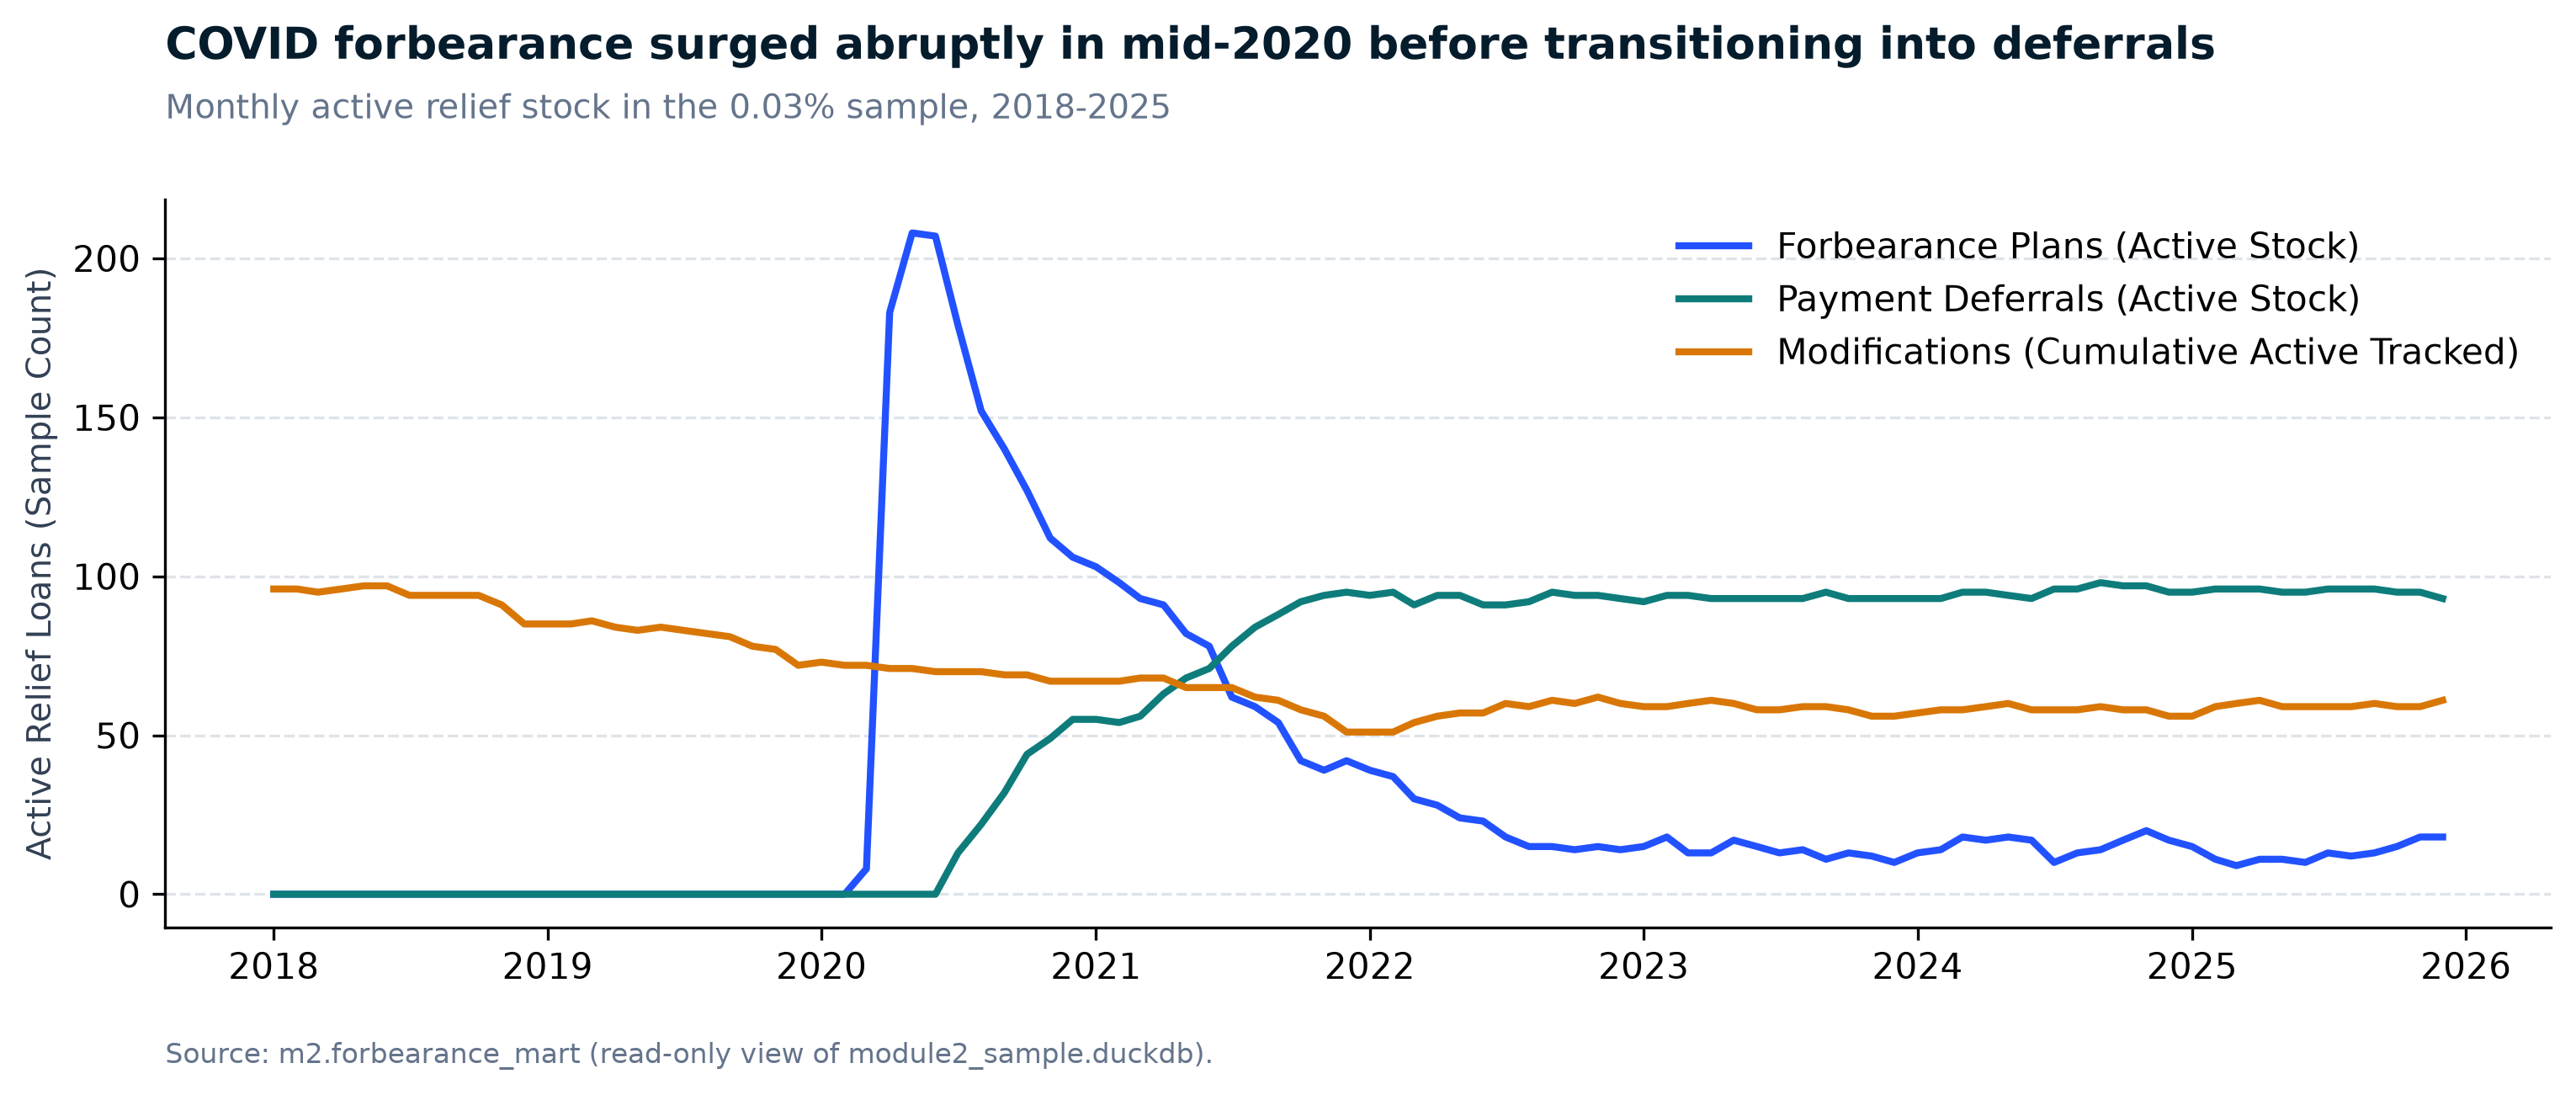

In [3]:
# Verify unique primary keys across both saved forbearance marts
# Check row count equals distinct composite key count with zero null key entries
for tbl, keys in [
    ("m2.forbearance_mart", "reporting_period, event_type"),
    ("m2.redefault_mart", "event_type, initial_status_on_entry, horizon_months, cohort_era"),
]:
    n_tot, n_dist = con.execute(f"SELECT count(*), count(DISTINCT ({keys})) FROM {tbl}").fetchone()
    assert n_tot == n_dist, f"Key duplicate in {tbl}"
    print(f"PASS  unique key on {tbl}: {n_tot:,} rows")

# Plot monthly active stock by relief mechanism from 2018 through 2025
# Pivot m2.forbearance_mart by reporting_period and render active waves cleanly via BytesIO
wave = con.execute("""
    SELECT reporting_period, event_type, active_stock
    FROM m2.forbearance_mart
    WHERE reporting_period >= DATE '2018-01-01'
    ORDER BY 1
""").fetchdf().pivot(index="reporting_period", columns="event_type", values="active_stock").fillna(0)

fig, ax = plt.subplots(figsize=(10.5, 4.3), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
dts = pd.to_datetime(wave.index)
for col_name, color, lbl in [
    ("forbearance_plan", "#2251FF", "Forbearance Plans (Active Stock)"),
    ("payment_deferral", "#0E7C7B", "Payment Deferrals (Active Stock)"),
    ("modification", "#D97706", "Modifications (Cumulative Active Tracked)"),
]:
    if col_name in wave.columns:
        ax.plot(dts, wave[col_name], color=color, linewidth=2.0, label=lbl, zorder=3)
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Active Relief Loans (Sample Count)", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="upper right")
fig.text(0.07, 0.94, "COVID forbearance surged abruptly in mid-2020 before transitioning into deferrals", fontsize=12.5, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Monthly active relief stock in the 0.03% sample, 2018-2025", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.forbearance_mart (read-only view of module2_sample.duckdb).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()